In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel(r'C:\Users\nikit\Downloads\insurance.xlsx')

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.select_dtypes(include = 'number').skew()

age         0.055673
bmi         0.284047
children    0.938380
charges     1.515880
dtype: float64

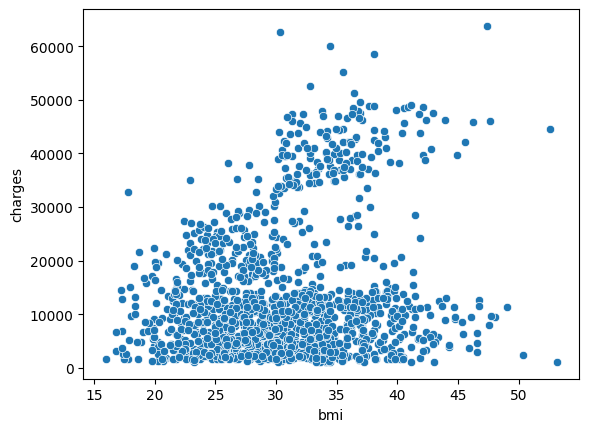

In [7]:
sns.scatterplot(x = df['bmi'] , y = df['charges'])
plt.show()

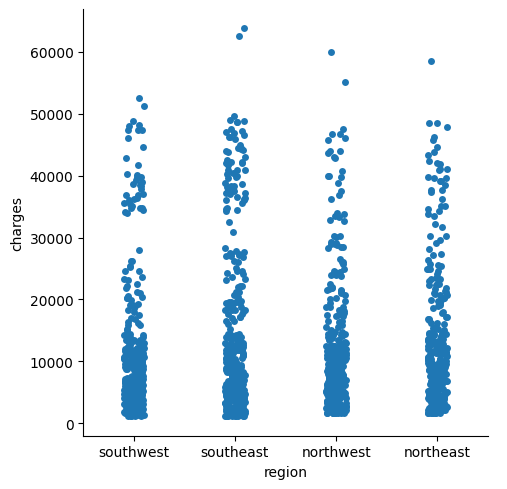

In [8]:
sns.catplot(x = 'region' , y = 'charges' , data = df)

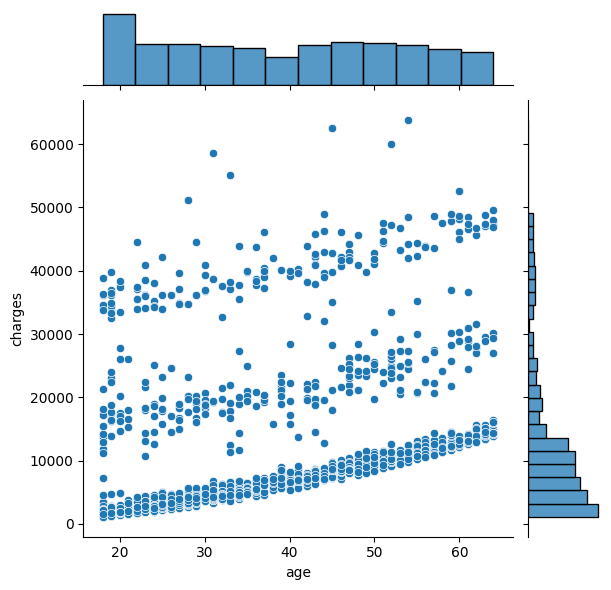

In [9]:
sns.jointplot(x = 'age' , y='charges' ,data = df)

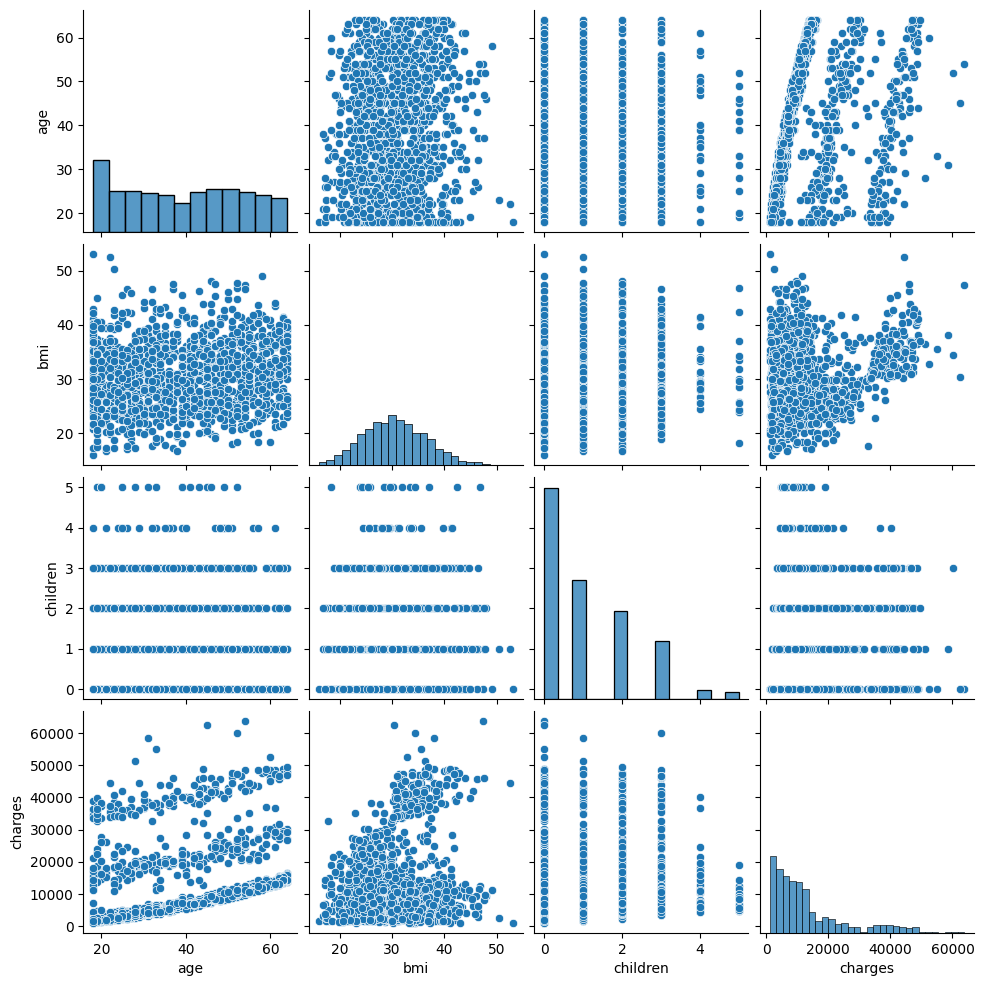

In [10]:
sns.pairplot(df)
plt.show()

<Axes: xlabel='bmi', ylabel='charges'>

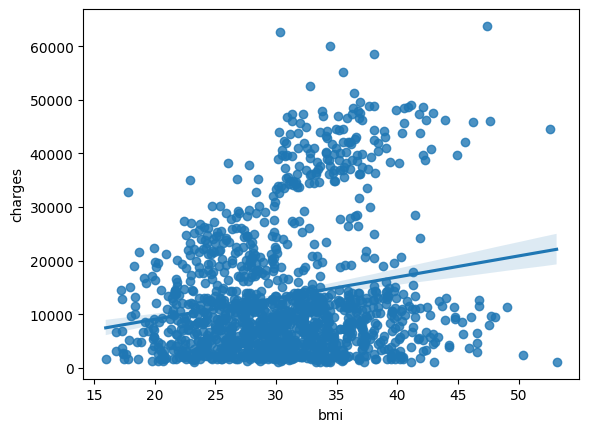

In [11]:
sns.regplot(x = 'bmi' , y='charges' ,data = df)

In [12]:
log = ['bmi', ] 

label = ['sex' , 'smoker', 'region']

plain = ['age' , 'children']

feature = log + label + plain

In [13]:
from sklearn.model_selection import train_test_split
x = df[feature]
y = df['charges']

In [14]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , random_state = 42)

In [15]:
x_train

,bmi,sex,smoker,region,age,children
560,19.950,female,no,northwest,46,2
1285,24.320,female,no,northeast,47,0
1142,24.860,female,no,southeast,52,0
969,34.320,female,no,southeast,39,5
486,21.470,female,no,northwest,54,3
...,...,...,...,...,...,...
1095,31.350,female,no,northeast,18,4
1130,23.870,female,no,southeast,39,5
1294,25.175,male,no,northeast,58,0
860,47.600,female,yes,southwest,37,2


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import  FunctionTransformer , StandardScaler , OneHotEncoder

In [17]:
log_pipeline = Pipeline(steps =[
    ('log', FunctionTransformer(np.log)),
     ('standard' , StandardScaler())
])

label_pipeline = Pipeline(steps = [
    ('OneHotEncoder' ,OneHotEncoder())
])

plain_pipeline = Pipeline(steps = [
    ('standard' , StandardScaler())
])

In [18]:
from sklearn.compose import ColumnTransformer

In [19]:
preprocess = ColumnTransformer(transformers = [
    ('log' , log_pipeline , log),
    ('label' , label_pipeline , label),
    ('standard',plain_pipeline,plain)
])

In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
lr_pipeline = Pipeline(steps =[
    ('preprocess', preprocess),
    ('Linear Regression',LinearRegression())
])

In [22]:
lr_pipeline.fit(x_train , y_train)

,steps,"[('preprocess', ...), ('Linear Regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('label', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
y_pred = lr_pipeline.predict(x_test)

In [24]:
from sklearn.metrics import r2_score

In [25]:
r2_score(y_test , y_pred)

0.7816610376217114

In [26]:
y_pred_train = lr_pipeline.predict(x_train)

In [27]:
r2_score(y_train , y_pred_train)

0.7428649358235366

In [28]:
from sklearn.ensemble import AdaBoostRegressor

In [29]:
ada = Pipeline(steps = [
    ('preprocess',preprocess),
    ('ada',AdaBoostRegressor())
])

In [30]:
ada.fit(x_train , y_train)

,steps,"[('preprocess', ...), ('ada', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('label', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
y_pred_ada = ada.predict(x_test)

In [32]:
r2_score(y_test , y_pred_ada)

0.7942132032598532

In [33]:
from xgboost import XGBRegressor

In [34]:
xgb = Pipeline(steps =[
    ('preprocess' ,preprocess),
    ('xgb',XGBRegressor(n_estimators = 100, learning_rate = 0.1,random_state = 42))
])

In [35]:
xgb.fit(x_train , y_train)

,steps,"[('preprocess', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('label', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:
y_pred_xgb= xgb.predict(x_test)

In [37]:
r2_score(y_test , y_pred_xgb)

0.8700709501873528

In [38]:
from sklearn.ensemble import RandomForestRegressor

In [39]:
clf = Pipeline(steps =[
    ('preprocess', preprocess),
    ('clf',RandomForestRegressor(n_estimators = 100 , random_state = 42))
])

In [40]:
y_pred_xgb_train = xgb.predict(x_train)
r2_score(y_train , y_pred_xgb_train)

0.9646864909052307

In [41]:
clf.fit(x_train , y_train)

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('log', ...), ('label', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [42]:
y_pred_clf = clf.predict(x_test)

In [43]:
r2_score(y_test , y_pred_clf )

0.8619900021115913

In [44]:
y_pred_clf_train = clf.predict(x_train)
r2_score(y_train , y_pred_clf_train)

0.9748689342162936

In [45]:
from sklearn.metrics import mean_absolute_error

In [46]:
print(mean_absolute_error(y_test , y_pred_xgb))

2446.8796330725863


In [47]:
from sklearn.model_selection import GridSearchCV ,RandomizedSearchCV

In [48]:
param_grid = {
    'xgb__n_estimators':[50,100,200,300,400,500,600,700,800,900,1000],
    'xgb__learning_rate':[(i*0.001) for i in range(0,100)],
    'xgb__max_depth' :[3,5,7,9,11]
}

In [49]:
random = RandomizedSearchCV(estimator=xgb,param_distributions=param_grid , cv=5,n_iter=20,random_state=42)

In [50]:
random.fit(x_train ,y_train)

,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'xgb__learning_rate': [0.0, 0.001, ...], 'xgb__max_depth': [3, 5, ...], 'xgb__n_estimators': [50, 100, ...]}"
,n_iter,20
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [51]:
print(random.best_params_)

{'xgb__n_estimators': 50, 'xgb__max_depth': 3, 'xgb__learning_rate': 0.098}


In [52]:
best_xgb = random.best_estimator_

In [53]:
y_pred_best_xgb = best_xgb.predict(x_test)

In [54]:
r2_score(y_test , y_pred_best_xgb)

0.8857960671337874

In [55]:
y_pred_best_xgb_train = best_xgb.predict(x_train)

In [56]:
r2_score(y_train,y_pred_best_xgb_train)

0.8791545329746636

In [57]:
import pandas as pd
results = pd.DataFrame(random.cv_results_)
results[['params','mean_test_score','std_test_score']].sort_values('mean_test_score', ascending=False).head()

,params,mean_test_score,std_test_score
1,"{'xgb__n_estimators': 50, 'xgb__max_depth': 3,...",0.848460,0.040012
2,"{'xgb__n_estimators': 100, 'xgb__max_depth': 3...",0.843161,0.041561
5,"{'xgb__n_estimators': 100, 'xgb__max_depth': 5...",0.832747,0.041846
11,"{'xgb__n_estimators': 400, 'xgb__max_depth': 3...",0.832628,0.041114
16,"{'xgb__n_estimators': 200, 'xgb__max_depth': 5...",0.827242,0.041350


In [58]:
results = {
    'Actual':y_test,
    'Predicted':y_pred_best_xgb
}

In [59]:
results = pd.DataFrame(results)

In [60]:
results

,Actual,Predicted
764,9095.06825,10535.073242
887,5272.17580,6014.393066
890,29330.98315,27061.541016
1293,9301.89355,9795.609375
259,33750.29180,34386.015625
...,...,...
109,47055.53210,45359.437500
575,12222.89830,12377.919922
535,6067.12675,7326.966309
543,63770.42801,47099.968750


In [61]:
results["Error"] = (results["Actual"] - results["Predicted"]).abs()
results["Error_%"] = (
    abs(results["Actual"] - results["Predicted"])
    / results["Actual"]
) * 100

print(results.sort_values("Error_%", ascending=False).head(20))

           Actual    Predicted         Error     Error_%
781    1146.79660  3017.815918   1871.019318  163.151802
808    1131.50660  2866.904297   1735.397697  153.370532
710    1727.54000  4119.377441   2391.837441  138.453375
358    1837.28190  4330.141113   2492.859213  135.681912
374    1391.52870  3227.412354   1835.883654  131.932863
247    1986.93340  4548.812988   2561.879588  128.936359
270    1719.43630  3931.227783   2211.791483  128.634686
478    1534.30450  3168.885254   1634.580754  106.535616
1114   2396.09590  4899.964355   2503.868455  104.497840
192    2137.65360  4360.663086   2223.009486  103.992971
410    1621.34020  3248.315430   1626.975230  100.347554
881    2789.05740  5484.882324   2695.824924   96.657205
974    2322.62180  4548.812988   2226.191188   95.848200
1097   1674.63230  3227.412354   1552.780054   92.723642
430   23082.95533  2406.667480  20676.287850   89.573833
614    1880.07000  3521.636963   1641.566963   87.314141
210    1980.07000  3684.111084 

In [62]:
results.median()

Actual       8487.880300
Predicted    9540.583984
Error        1600.544246
Error_%        20.861037
dtype: float64

In [63]:
results.mean()

Actual       12968.317063
Predicted    13196.147461
Error         2414.760804
Error_%         31.618801
dtype: float64